## Part 1

### Data classification_copus.scv
- Data phân gồm 400 bài báo về kinh doanh và công nghệ
- Part 1 phân loại các nhãn đó
- Part 2 là là chức năng search
- 

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.metrics.pairwise import cosine_similarity

RANDOM_STATE = 42
DATA_PATH = Path("classification_corpus.csv")  # TODO: sửa nếu tên file khác
pd.set_option("display.max_colwidth", 110)

In [2]:
## Load data
with open(DATA_PATH, "r", encoding="utf-8") as f:
    df = pd.read_csv(f)

df.head(10)

,id,url,source,category,title,description,text,processed_text
0,CLS0001,https://example.edu.vn/nlp/classification/1,NLP teaching fallback (synthetic),Công nghệ,An ninh mạng bổ sung tính năng bảo mật,Thông tin mới về an ninh mạng đang thu hút sự chú ý.,An ninh mạng bổ sung tính năng bảo mật. Thông tin mới về an ninh mạng đang thu hút sự chú ý. Hệ thống sử d...,an_ninh_mạng bổ sung tính năng bảo mật thông tin mới về an_ninh_mạng đang thu hút sự chú ý hệ thống sử dụn...
1,CLS0002,https://example.edu.vn/nlp/classification/2,NLP teaching fallback (synthetic),Công nghệ,Thiết bị đeo mở rộng khả năng kết nối,Thông tin mới về thiết bị đeo đang thu hút sự chú ý.,Thiết bị đeo mở rộng khả năng kết nối. Thông tin mới về thiết bị đeo đang thu hút sự chú ý. Sản phẩm mới h...,thiết bị đeo mở rộng khả năng kết nối thông tin mới về thiết bị đeo đang thu hút sự chú ý sản phẩm mới hỗ ...
2,CLS0003,https://example.edu.vn/nlp/classification/3,NLP teaching fallback (synthetic),Công nghệ,Thiết bị đeo được giới thiệu tại sự kiện công nghệ,Thông tin mới về thiết bị đeo đang thu hút sự chú ý.,Thiết bị đeo được giới thiệu tại sự kiện công nghệ. Thông tin mới về thiết bị đeo đang thu hút sự chú ý. S...,thiết bị đeo được giới thiệu tại sự kiện công_nghệ thông tin mới về thiết bị đeo đang thu hút sự chú ý sản...
3,CLS0004,https://example.edu.vn/nlp/classification/4,NLP teaching fallback (synthetic),Kinh doanh,Cổ phiếu thay đổi chính sách giá,Thông tin mới về cổ phiếu đang thu hút sự chú ý.,Cổ phiếu thay đổi chính sách giá. Thông tin mới về cổ phiếu đang thu hút sự chú ý. Nhà đầu tư theo dõi sát...,cổ phiếu thay đổi chính sách giá thông tin mới về cổ phiếu đang thu hút sự chú ý nhà_đầu_tư theo dõi sát b...
4,CLS0005,https://example.edu.vn/nlp/classification/5,NLP teaching fallback (synthetic),Kinh doanh,Doanh nghiệp xuất khẩu mở rộng đầu tư trong quý tới,Thông tin mới về doanh nghiệp xuất khẩu đang thu hút sự chú ý.,Doanh nghiệp xuất khẩu mở rộng đầu tư trong quý tới. Thông tin mới về doanh nghiệp xuất khẩu đang thu hút ...,doanh_nghiệp xuất khẩu mở rộng đầu tư trong quý tới thông tin mới về doanh_nghiệp xuất khẩu đang thu hút s...
5,CLS0006,https://example.edu.vn/nlp/classification/6,NLP teaching fallback (synthetic),Công nghệ,Phần mềm doanh nghiệp mở rộng khả năng kết nối,Thông tin mới về phần mềm doanh nghiệp đang thu hút sự chú ý.,Phần mềm doanh nghiệp mở rộng khả năng kết nối. Thông tin mới về phần mềm doanh nghiệp đang thu hút sự chú...,phần mềm doanh_nghiệp mở rộng khả năng kết nối thông tin mới về phần mềm doanh_nghiệp đang thu hút sự chú ...
6,CLS0007,https://example.edu.vn/nlp/classification/7,NLP teaching fallback (synthetic),Kinh doanh,Giá vàng ghi nhận nhu cầu phục hồi,Thông tin mới về giá vàng đang thu hút sự chú ý.,Giá vàng ghi nhận nhu cầu phục hồi. Thông tin mới về giá vàng đang thu hút sự chú ý. Các chuyên gia cho rằ...,giá vàng ghi nhận nhu cầu phục hồi thông tin mới về giá vàng đang thu hút sự chú ý các chuyên gia cho rằng...
7,CLS0008,https://example.edu.vn/nlp/classification/8,NLP teaching fallback (synthetic),Kinh doanh,Bất động sản mở rộng đầu tư trong quý tới,Thông tin mới về bất động sản đang thu hút sự chú ý.,Bất động sản mở rộng đầu tư trong quý tới. Thông tin mới về bất động sản đang thu hút sự chú ý. Nhà đầu tư...,bất_động_sản mở rộng đầu tư trong quý tới thông tin mới về bất_động_sản đang thu hút sự chú ý nhà_đầu_tư t...
8,CLS0009,https://example.edu.vn/nlp/classification/9,NLP teaching fallback (synthetic),Công nghệ,Quỹ đầu tư công bố kết quả kinh doanh mới,Thông tin mới về quỹ đầu tư đang thu hút sự chú ý.,Quỹ đầu tư công bố kết quả kinh doanh mới. Thông tin mới về quỹ đầu tư đang thu hút sự chú ý. Báo cáo mới ...,quỹ đầu tư công bố kết quả kinh_doanh mới thông tin mới về quỹ đầu tư đang thu hút sự chú ý báo cáo mới ch...
9,CLS0010,https://example.edu.vn/nlp/classification/10,NLP teaching fallback (synthetic),Công nghệ,Robot ra mắt phiên bản mới,Thông tin mới về robot đang thu hút sự chú ý.,Robot ra mắt phiên bản mới. Thông t

In [3]:
TEXT_COL = "processed_text"
LABEL_COL = "category"
TITLE_COL = "title"

required = [TEXT_COL, LABEL_COL]
missing = [col for col in required if col not in df.columns]
if missing:
    raise KeyError(f"Thiếu cột {missing}; các cột hiện có: {df.columns.tolist()}")

work = df.dropna(subset=required).copy()
work[TEXT_COL] = work[TEXT_COL].astype(str).str.strip()
work[LABEL_COL] = work[LABEL_COL].astype(str).str.strip()
work = work[(work[TEXT_COL] != "") & (work[LABEL_COL] != "")].copy()

print("Rows usable:", len(work))
print("Missing text:", df[TEXT_COL].isna().sum())
print("Duplicate processed texts:", work[TEXT_COL].duplicated().sum())
print("Label distribution:")
display(work[LABEL_COL].value_counts().rename_axis("label").to_frame("count"))

if "source" in work.columns:
    print("Sources:")
    display(work["source"].value_counts().head(10))

Rows usable: 400
Missing text: 0
Duplicate processed texts: 6
Label distribution:


,count
label,
Kinh doanh,240
Công nghệ,160


Sources:


source
NLP teaching fallback (synthetic)    400
Name: count, dtype: int64

In [4]:
work = work.drop_duplicates(subset=[TEXT_COL]).copy()

print("Rows after removing duplicates:", len(work))
print("Duplicates remaining:", work[TEXT_COL].duplicated().sum())

Rows after removing duplicates: 394
Duplicates remaining: 0


In [5]:
def clean_text(text):
    """Làm sạch nhẹ; giữ dấu tiếng Việt và dấu _ trong token đã segment."""
    text = str(text).lower().strip()
    text = re.sub(r"\s+", " ", text)
    return text

work["clean_text"] = work[TEXT_COL].map(clean_text)

# Minh họa tokenization đơn giản; vectorizer sẽ tự tokenize khi fit/transform.
example = work["clean_text"].iloc[0]
print("Before:", example[:220])
print("Tokens (demo):", example.split()[:25])

Before: an_ninh_mạng bổ sung tính năng bảo mật thông tin mới về an_ninh_mạng đang thu hút sự chú ý hệ thống sử dụng thuật toán mới để xử lý dữ liệu nhanh hơn và giảm độ trễ
Tokens (demo): ['an_ninh_mạng', 'bổ', 'sung', 'tính', 'năng', 'bảo', 'mật', 'thông', 'tin', 'mới', 'về', 'an_ninh_mạng', 'đang', 'thu', 'hút', 'sự', 'chú', 'ý', 'hệ', 'thống', 'sử', 'dụng', 'thuật', 'toán', 'mới']


### Part1 Text Classification

#### Split data


In [6]:
X = work["clean_text"]
y = work[LABEL_COL]

X_train , X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", len(X_train), "Test:", len(X_test))
print("Train labels:", y_train.value_counts().to_dict())
print("Test labels:", y_test.value_counts().to_dict())

Train: 315 Test: 79
Train labels: {'Kinh doanh': 189, 'Công nghệ': 126}
Test labels: {'Kinh doanh': 48, 'Công nghệ': 31}


In [7]:
def make_pipeline(classifier):
    return Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=1)),
        ("model", classifier)
    ])

models = {
    "Multinomial Naive Bayes": make_pipeline(MultinomialNB()),
    "Logistic Regression": make_pipeline(
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    )
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(f"Trained: {name}")

Trained: Multinomial Naive Bayes
Trained: Logistic Regression


In [8]:
rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "F1_weighted": f1_score(y_test, pred, average="weighted", zero_division=0),
    })
comparison = pd.DataFrame(rows).sort_values("F1_macro", ascending=False).reset_index(drop=True)
display(comparison.round(4))

for name, pred in predictions.items():
    print("\n", name)
    print(classification_report(y_test, pred, zero_division=0))

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted
0,Logistic Regression,0.9367,0.9318,0.9365,0.9340,0.9369
1,Multinomial Naive Bayes,0.9241,0.9204,0.9204,0.9204,0.9241



 Multinomial Naive Bayes
              precision    recall  f1-score   support

   Công nghệ       0.90      0.90      0.90        31
  Kinh doanh       0.94      0.94      0.94        48

    accuracy                           0.92        79
   macro avg       0.92      0.92      0.92        79
weighted avg       0.92      0.92      0.92        79


 Logistic Regression
              precision    recall  f1-score   support

   Công nghệ       0.91      0.94      0.92        31
  Kinh doanh       0.96      0.94      0.95        48

    accuracy                           0.94        79
   macro avg       0.93      0.94      0.93        79
weighted avg       0.94      0.94      0.94        79



#### Confision matrix

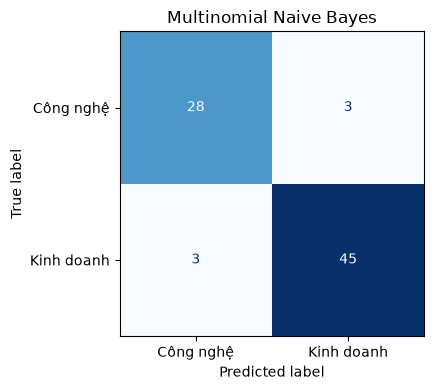

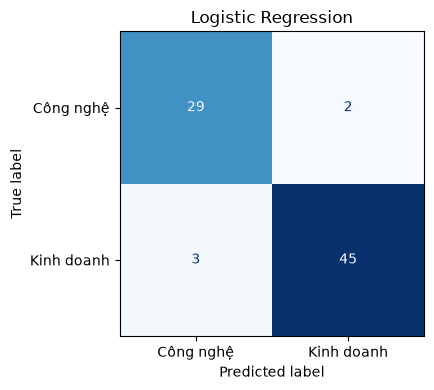

In [9]:
for name, pred in predictions.items():
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    plt.tight_layout()
    plt.show()

7. Error Analysis — ít nhất 5 dự đoán sai

In [10]:
error_tables = {}

for model_name, predicted_labels in predictions.items():
    # 1. Lấy các bài viết trong tập Test
    results = work.loc[X_test.index, [TITLE_COL]].copy()
    results["text"] = X_test
    results["true_label"] = y_test
    results["predicted_label"] = predicted_labels

    # 2. Chọn những bài model dự đoán sai
    wrong_predictions = (
        results["true_label"] != results["predicted_label"]
    )
    errors = results.loc[wrong_predictions].copy()

    # 3. Lưu kết quả của từng model
    error_tables[model_name] = errors

    # 4. Hiển thị tối đa 5 bài dự đoán sai
    print(f"{model_name}: {len(errors)} dự đoán sai")
    display(errors.head(5))

Multinomial Naive Bayes: 6 dự đoán sai


,title,text,true_label,predicted_label
217,Công nghệ pin nâng cấp thuật toán xử lý dữ liệu,công_nghệ pin nâng cấp thuật toán xử lý dữ liệu thông tin mới về công_nghệ pin đang thu hút sự chú ý hệ th...,Kinh doanh,Công nghệ
20,An ninh mạng được thử nghiệm trên quy mô lớn,an_ninh_mạng được thử nghiệm trên quy mô lớn thông tin mới về an_ninh_mạng đang thu hút sự chú ý hệ thống ...,Kinh doanh,Công nghệ
172,Nền tảng số mở rộng khả năng kết nối,nền_tảng_số mở rộng khả năng kết nối thông tin mới về nền_tảng_số đang thu hút sự chú ý giải pháp được thi...,Kinh doanh,Công nghệ
271,Startup công bố kết quả kinh doanh mới,startup công bố kết quả kinh_doanh mới thông tin mới về startup đang thu hút sự chú ý thị trường phản ứng ...,Công nghệ,Kinh doanh
132,Doanh nghiệp xuất khẩu đặt mục tiêu tăng trưởng năm nay,doanh_nghiệp xuất khẩu đặt mục tiêu tăng trưởng năm nay thông tin mới về doanh_nghiệp xuất khẩu đang thu h...,Công nghệ,Kinh doanh


Logistic Regression: 5 dự đoán sai


,title,text,true_label,predicted_label
217,Công nghệ pin nâng cấp thuật toán xử lý dữ liệu,công_nghệ pin nâng cấp thuật toán xử lý dữ liệu thông tin mới về công_nghệ pin đang thu hút sự chú ý hệ th...,Kinh doanh,Công nghệ
20,An ninh mạng được thử nghiệm trên quy mô lớn,an_ninh_mạng được thử nghiệm trên quy mô lớn thông tin mới về an_ninh_mạng đang thu hút sự chú ý hệ thống ...,Kinh doanh,Công nghệ
172,Nền tảng số mở rộng khả năng kết nối,nền_tảng_số mở rộng khả năng kết nối thông tin mới về nền_tảng_số đang thu hút sự chú ý giải pháp được thi...,Kinh doanh,Công nghệ
132,Doanh nghiệp xuất khẩu đặt mục tiêu tăng trưởng năm nay,doanh_nghiệp xuất khẩu đặt mục tiêu tăng trưởng năm nay thông tin mới về doanh_nghiệp xuất khẩu đang thu h...,Công nghệ,Kinh doanh
155,Cổ phiếu công bố kết quả kinh doanh mới,cổ phiếu công bố kết quả kinh_doanh mới thông tin mới về cổ phiếu đang thu hút sự chú ý báo cáo mới cho th...,Công nghệ,Kinh doanh


| Mẫu sai | Quan sát | Giả thuyết nguyên nhân | Hướng cải thiện |
|---|---|---|---|
| **Index 217 — Công nghệ pin nâng cấp thuật toán xử lý dữ liệu** | Nhãn thật: **Kinh doanh** → dự đoán: **Công nghệ**. Có các cụm “thuật toán”, “xử lý dữ liệu”, “giảm độ trễ”, nhưng cuối bài nhấn mạnh “hiệu quả tài chính và thị trường”. | Chủ đề giao thoa. Những từ mô tả kỹ thuật có thể ảnh hưởng mạnh hơn câu xác định trọng tâm kinh doanh. | Kiểm tra đóng góp của các từ vào dự đoán; bổ sung bài về kinh doanh trong lĩnh vực công nghệ. |
| **Index 20 — An ninh mạng được thử nghiệm trên quy mô lớn** | Nhãn thật: **Kinh doanh** → dự đoán: **Công nghệ**. Nội dung nói về an ninh mạng, thuật toán và độ trễ; không thấy thông tin kinh doanh rõ ràng. | Có thể nhãn chưa phù hợp với nội dung hoặc văn bản tổng hợp thiếu ngữ cảnh giải thích nhãn. Chưa đủ bằng chứng kết luận nhãn sai. | Rà soát nhãn và quy tắc gán nhãn; xác minh trước khi sửa dữ liệu. |
| **Index 172 — Nền tảng số mở rộng khả năng kết nối** | Nhãn thật: **Kinh doanh** → dự đoán: **Công nghệ**. Các cụm “kết nối”, “môi trường số”, “tốc độ”, “bảo mật” xuất hiện cùng “hiệu quả kinh doanh”. | Nội dung giao thoa, phần kỹ thuật nổi bật hơn phần kinh doanh vốn khá chung chung. | Làm rõ tiêu chí phân loại theo trọng tâm bài; thêm mẫu giao thoa có nhãn được kiểm tra. |
| **Index 132 — Doanh nghiệp xuất khẩu đặt mục tiêu tăng trưởng năm nay** | Nhãn thật: **Công nghệ** → dự đoán: **Kinh doanh**. Nội dung nhắc “doanh thu”, “lợi nhuận”, “dòng tiền”; công nghệ chỉ được đề cập ở câu cuối. | Từ vựng tài chính có thể chi phối dự đoán. Nhãn Công nghệ cũng cần được rà soát vì bài chưa mô tả công nghệ cụ thể. | Kiểm tra lại nhãn; bổ sung nội dung công nghệ cụ thể nếu văn bản bị thiếu thông tin. |
| **Index 155 — Cổ phiếu công bố kết quả kinh doanh mới** | Nhãn thật: **Công nghệ** → dự đoán: **Kinh doanh**. Tiêu đề và thân bài nói về cổ phiếu, doanh thu, lợi nhuận; câu cuối lại nói trọng tâm là “sản phẩm, hệ thống và kỹ thuật”. | Văn bản tổng hợp có thể ghép các câu thiếu nhất quán. Model có thể dựa nhiều vào từ vựng kinh doanh ở phần đầu. | Kiểm tra tính nhất quán giữa tiêu đề, nội dung và nhãn; bổ sung dữ liệu thực được gán nhãn rõ ràng. |

## Part 2 — Simple Text Search
Dùng toàn bộ dữ liệu `work` đã loại trùng từ Part 1. Chạy Part 1 trước phần này.
TF-IDF được fit trên toàn bộ kho bài để lập chỉ mục; query chỉ dùng `transform`.


### 1. Chuẩn bị tài liệu và tách từ
Dùng nội dung gốc `text` và Underthesea để tách từ nhất quán cho cả bài viết và query.
Giữ index gốc để tra cứu lại bài. Nhãn category chỉ để hiển thị, không dùng để xếp hạng.


In [11]:
from underthesea import word_tokenize

search_docs = work.dropna(subset=["text"]).copy()
search_docs = search_docs[search_docs["text"].str.strip() != ""].copy()

def prepare_query(text):
    return word_tokenize(clean_text(text), format="text")

search_docs["search_text"] = search_docs["text"].map(prepare_query)
print("Documents:", len(search_docs))
display(search_docs[[TITLE_COL, LABEL_COL, "search_text"]].head())


d:\TrainAI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Documents: 394


,title,category,search_text
0,An ninh mạng bổ sung tính năng bảo mật,Công nghệ,an_ninh mạng bổ_sung tính_năng bảo_mật . thông_tin mới về an_ninh_mạng đang thu_hút sự chú_ý . hệ_thống sử...
1,Thiết bị đeo mở rộng khả năng kết nối,Công nghệ,thiết_bị đeo mở_rộng khả_năng kết_nối . thông_tin mới về thiết_bị đeo đang thu_hút sự chú_ý . sản_phẩm mới...
2,Thiết bị đeo được giới thiệu tại sự kiện công nghệ,Công nghệ,thiết_bị đeo được giới_thiệu tại sự_kiện công_nghệ . thông_tin mới về thiết_bị đeo đang thu_hút sự chú_ý ....
3,Cổ phiếu thay đổi chính sách giá,Kinh doanh,cổ_phiếu thay_đổi chính_sách giá . thông_tin mới về cổ_phiếu đang thu_hút sự chú_ý . nhà_đầu_tư theo_dõi s...
4,Doanh nghiệp xuất khẩu mở rộng đầu tư trong quý tới,Kinh doanh,doanh_nghiệp xuất_khẩu mở_rộng đầu_tư trong quý tới . thông_tin mới về doanh_nghiệp xuất_khẩu đang thu_hút...


### 2. Chuyển tài liệu thành TF-IDF
Mỗi dòng là một tài liệu; mỗi cột là một từ hoặc cụm hai từ.


In [12]:
search_vectorizer = TfidfVectorizer(ngram_range=(1, 2))
document_vectors = search_vectorizer.fit_transform(search_docs["search_text"])
print("TF-IDF shape:", document_vectors.shape)


TF-IDF shape: (394, 724)


### 3. Nhập query và trả về top 5
Sửa biến `query` rồi chạy lại cell tìm kiếm. Cosine similarity càng cao thì mức
khớp TF-IDF càng lớn, không phải xác suất bài viết đúng với nhu cầu.
Nếu không có từ khớp, trả bảng rỗng; nếu ít hơn 5 bài có điểm dương, chỉ trả những bài đó.


In [13]:
def search_tfidf(query, top_k=5):
    if not query.strip():
        raise ValueError("Hãy nhập query có nội dung.")
    if top_k < 1:
        raise ValueError("top_k phải lớn hơn 0.")

    query_vector = search_vectorizer.transform([prepare_query(query)])
    scores = cosine_similarity(query_vector, document_vectors).ravel()
    results = search_docs[[TITLE_COL, LABEL_COL, "text"]].copy()
    results["score"] = scores
    return results[results["score"] > 0].sort_values(
        "score", ascending=False, kind="stable"
    ).head(top_k)

query = "bảo mật dữ liệu và an ninh mạng"
tfidf_results = search_tfidf(query)
print("Query:", query)
if tfidf_results.empty:
    print("Không có từ khóa khớp trong kho tài liệu.")
else:
    display(tfidf_results)


Query: bảo mật dữ liệu và an ninh mạng


,title,category,text,score
0,An ninh mạng bổ sung tính năng bảo mật,Công nghệ,An ninh mạng bổ sung tính năng bảo mật. Thông tin mới về an ninh mạng đang thu hút sự chú ý. Hệ thống sử d...,0.426023
241,An ninh mạng nâng cấp thuật toán xử lý dữ liệu,Công nghệ,An ninh mạng nâng cấp thuật toán xử lý dữ liệu. Thông tin mới về an ninh mạng đang thu hút sự chú ý. Hệ th...,0.371667
38,An ninh mạng hỗ trợ người dùng tự động hóa công việc,Công nghệ,An ninh mạng hỗ trợ người dùng tự động hóa công việc. Thông tin mới về an ninh mạng đang thu hút sự chú ý....,0.354903
175,An ninh mạng ra mắt phiên bản mới,Công nghệ,An ninh mạng ra mắt phiên bản mới. Thông tin mới về an ninh mạng đang thu hút sự chú ý. Nhà phát triển tập...,0.333867
391,Trung tâm dữ liệu nâng cấp thuật toán xử lý dữ liệu,Công nghệ,Trung tâm dữ liệu nâng cấp thuật toán xử lý dữ liệu. Thông tin mới về trung tâm dữ liệu đang thu hút sự ch...,0.127640


### 4. Hạn chế của keyword search
- Khó nối các cách diễn đạt đồng nghĩa nếu không có từ chung, ví dụ “bảo vệ thông tin” và “an ninh mạng”.
- Từ đa nghĩa hoặc từ chung có thể đưa bài không phù hợp lên cao.
- Chưa hiểu tốt phủ định và ngữ cảnh; bigram chỉ bổ sung ngữ cảnh ngắn.
- Phụ thuộc vào tách từ, chính tả và từ vựng của kho bài.
- Dữ liệu tổng hợp có nhiều câu theo mẫu, nên điểm cao có thể do trùng mẫu câu.

Đọc nội dung top 5 để đánh giá mức liên quan; nhãn phân loại không thay thế nhãn relevance cho query.


## Bonus — So sánh với embedding semantic search
Dùng cùng kho bài và cùng query. Embedding nhận văn bản gốc, model tự tokenize.

Phần bonus cần `sentence-transformers` và tải model ở lần chạy đầu.
Nếu cần cài, chạy `%pip install sentence-transformers` trong một cell riêng,
sau đó đổi `RUN_BONUS = True` bên dưới. TF-IDF chạy độc lập với phần này.

Model: [paraphrase-multilingual-MiniLM-L12-v2](https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2).
Cách dùng: [Sentence Transformers](https://www.sbert.net/docs/quickstart.html).


In [17]:
RUN_BONUS = True
semantic_model = None
semantic_vectors = None

if RUN_BONUS:
    from sentence_transformers import SentenceTransformer

    semantic_model = SentenceTransformer(
        "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
    )
    semantic_vectors = semantic_model.encode(
        search_docs["text"].tolist(), normalize_embeddings=True,
        convert_to_numpy=True, show_progress_bar=True
    )
    print("Embedding shape:", semantic_vectors.shape)
else:
    print("Bonus chưa bật. Cài sentence-transformers và đặt RUN_BONUS = True để chạy.")


Batches: 100%|██████████| 13/13 [00:04<00:00,  2.96it/s]

Embedding shape: (394, 384)


In [18]:
def search_semantic(query, top_k=5):
    if semantic_model is None:
        raise RuntimeError("Hãy chạy cell nạp model với RUN_BONUS = True.")
    if not query.strip() or top_k < 1:
        raise ValueError("Query phải có nội dung và top_k phải lớn hơn 0.")
    query_vector = semantic_model.encode(
        [query], normalize_embeddings=True, convert_to_numpy=True
    )
    scores = cosine_similarity(query_vector, semantic_vectors).ravel()
    results = search_docs[[TITLE_COL, LABEL_COL, "text"]].copy()
    results["score"] = scores
    return results.sort_values("score", ascending=False, kind="stable").head(top_k)

semantic_results = None
if semantic_model is not None:
    tfidf_results = search_tfidf(query)
    semantic_results = search_semantic(query)
    print("Query:", query)
    display(pd.concat({
        "TF-IDF": tfidf_results,
        "Semantic": semantic_results
    }, names=["Method", "Row index"]))


Query: bảo mật dữ liệu và an ninh mạng


title  \
Method   Row index                                                         
TF-IDF   0                        An ninh mạng bổ sung tính năng bảo mật   
         241              An ninh mạng nâng cấp thuật toán xử lý dữ liệu   
         38         An ninh mạng hỗ trợ người dùng tự động hóa công việc   
         175                           An ninh mạng ra mắt phiên bản mới   
         391         Trung tâm dữ liệu nâng cấp thuật toán xử lý dữ liệu   
Semantic 0                        An ninh mạng bổ sung tính năng bảo mật   
         38         An ninh mạng hỗ trợ người dùng tự động hóa công việc   
         78                  An ninh mạng được tích hợp vào sản phẩm mới   
         215                   An ninh mạng giảm mức tiêu thụ năng lượng   
         20                 An ninh mạng được thử nghiệm trên quy mô lớn   

                      category  \
Method   Row index               
TF-IDF   0           Công nghệ   
         241         Công nghệ   
         38          Công nghệ   
         175         Công nghệ   
         391         Công nghệ   
Semantic 0           Công nghệ   
         38          Công nghệ   
         78          Công nghệ   
         215         Công nghệ   
         20         Kinh doanh   

                                                                                                                             text  \
Method   Row index                                                                                                                  
TF-IDF   0          An ninh mạng bổ sung tính năng bảo mật. Thông tin mới về an ninh mạng đang thu hút sự chú ý. Hệ thống sử d...   
         241        An ninh mạng nâng cấp thuật toán xử lý dữ liệu. Thông tin mới về an ninh mạng đang thu hút sự chú ý. Hệ th...   
         38         An ninh mạng hỗ trợ người dùng tự động hóa công việc. Thông tin mới về an ninh mạng đang thu hút sự chú ý....   
         175        An ninh mạng ra mắt phiên bản mới. Thông tin mới về an ninh mạng đang thu hút sự chú ý. Nhà phát triển tập...   
         391        Trung tâm dữ liệu nâng cấp thuật toán xử lý dữ liệu. Thông tin mới về trung tâm dữ liệu đang thu hút sự ch...   
Semantic 0          An ninh mạng bổ sung tính năng bảo mật. Thông tin mới về an ninh mạng đang thu hút sự chú ý. Hệ thống sử d...   
         38         An ninh mạng hỗ trợ người dùng tự động hóa công việc. Thông tin mới về an ninh mạng đang thu hút sự chú ý....   
         78         An ninh mạng được tích hợp vào sản phẩm mới. Thông tin mới về an ninh mạng đang thu hút sự chú ý. Hệ thống...   
         215        An ninh mạng giảm mức tiêu thụ năng lượng. Thông tin mới về an ninh mạng đang thu hút sự chú ý. Giải pháp ...   
         20         An ninh mạng được thử nghiệm trên quy mô lớn. Thông tin mới về an ninh mạng đang thu hút sự chú ý. Hệ thốn...   

                       score  
Method   Row index            
TF-IDF   0          0.426023  
         241        0.371667  
         38         0.354903  
         175        0.333867  
         391        0.127640  
Semantic 0          0.695200  
         38         0.694971  
         78         0.667046  
         215        0.662246  
         20         0.645665

### Nhận xét cách nào tốt hơn
- Query có đúng từ khóa hoặc tên riêng: TF-IDF có thể phù hợp và dễ giải thích qua từ khớp.
- Query diễn đạt lại ý, dùng từ đồng nghĩa: semantic search có thể tìm bài liên quan dù ít từ chung.
- Semantic search vẫn có thể trả bài chỉ gần chủ đề; tài liệu dài cũng có thể bị model cắt bớt.
- Không so sánh trực tiếp độ lớn score của hai phương pháp để chọn bên thắng.

Để kết luận trên query đang thử, đọc các bài trong hợp của hai top 5 và đánh dấu
index bài thực sự đáp ứng nhu cầu. Nhập các index đó vào `relevant_rows` bên dưới.
Chưa có đánh giá relevance thì chưa đủ bằng chứng kết luận phương pháp nào tốt hơn.


In [19]:
# Điền set index của các bài liên quan sau khi đọc, ví dụ cú pháp: {12, 34}.
# Các số ví dụ không phải nhãn relevance đã được xác minh.
relevant_rows = None

if semantic_results is not None and relevant_rows is not None:
    evaluations = []
    for method, results in {"TF-IDF": tfidf_results, "Semantic": semantic_results}.items():
        relevant_count = len(set(results.index) & set(relevant_rows))
        evaluations.append({
            "Method": method, "Relevant in top 5": relevant_count,
            "Precision@5": relevant_count / 5
        })
    search_comparison = pd.DataFrame(evaluations).sort_values("Precision@5", ascending=False)
    display(search_comparison)
    if search_comparison["Precision@5"].nunique() == 1:
        print("Hai phương pháp bằng nhau theo Precision@5 trên query này.")
    else:
        print("Tốt hơn trên query này:", search_comparison.iloc[0]["Method"])
        print("Lý do: tìm được nhiều bài đã đánh dấu liên quan hơn trong top 5.")
else:
    print("Chạy bonus và đánh dấu relevant_rows để so sánh chất lượng thực tế.")


Chạy bonus và đánh dấu relevant_rows để so sánh chất lượng thực tế.
